# EcoSort AI – Waste Classification Model
## 1. Importing Required Libraries
This notebook is used to develop an AI-based waste classification
system using Convolutional Neural Networks (CNN) and MobileNetV2.

The model will classify waste images into 10 categories.

In [2]:
# Import basic libraries
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Import TensorFlow
import tensorflow as tf

# Import Keras components
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Import evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Display library version
print("TensorFlow Version:", tf.__version__)

print("All libraries imported successfully!")

TensorFlow Version: 2.18.0
All libraries imported successfully!


## 2. Defining Project and Dataset Paths

In this section, we define the location of the EcoSort AI project,
dataset folders and model-saving directory.

In [4]:
# Main project directory
PROJECT_DIR = r"C:\Users\DELL\Documents\EcoSort-AI"

# Dataset directory
DATA_DIR = os.path.join(PROJECT_DIR, "data")

# Training, validation and testing directories
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VALIDATION_DIR = os.path.join(DATA_DIR, "validation")
TEST_DIR = os.path.join(DATA_DIR, "test")

# Directory to save trained models
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

# Create models folder if it does not exist
os.makedirs(MODEL_DIR, exist_ok=True)

# Check whether directories exist
print("Project Directory:", os.path.exists(PROJECT_DIR))
print("Training Directory:", os.path.exists(TRAIN_DIR))
print("Validation Directory:", os.path.exists(VALIDATION_DIR))
print("Testing Directory:", os.path.exists(TEST_DIR))
print("Models Directory:", os.path.exists(MODEL_DIR))

Project Directory: True
Training Directory: True
Validation Directory: True
Testing Directory: True
Models Directory: True


## 3. Dataset Structure Verification

In this section, we check whether all three dataset folders
contain the correct waste categories.

In [5]:
# Dataset splits
splits = {
    "Training": TRAIN_DIR,
    "Validation": VALIDATION_DIR,
    "Testing": TEST_DIR
}

dataset_classes = {}

for split_name, split_path in splits.items():

    print("\n", split_name, "Dataset")

    classes = sorted([
        folder for folder in os.listdir(split_path)
        if os.path.isdir(os.path.join(split_path, folder))
    ])

    dataset_classes[split_name] = classes

    print("Classes:", classes)
    print("Number of classes:", len(classes))

# Compare categories
if (
    dataset_classes["Training"] ==
    dataset_classes["Validation"] ==
    dataset_classes["Testing"]
):
    print("\nSUCCESS: All datasets contain identical classes.")

else:
    print("\nWARNING: Dataset classes do not match!")


 Training Dataset
Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of classes: 10

 Validation Dataset
Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of classes: 10

 Testing Dataset
Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of classes: 10

SUCCESS: All datasets contain identical classes.


## 4. Dataset Image Count

This section calculates the number of images available in
each waste category for training, validation and testing.

In [7]:
# Supported image formats
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

dataset_counts = {}

for split_name, split_path in splits.items():

    print("\n", split_name, "Dataset")
    print("-" * 40)

    total_images = 0

    for class_name in dataset_classes[split_name]:

        class_path = os.path.join(split_path, class_name)

        images = [
            file for file in os.listdir(class_path)
            if file.lower().endswith(image_extensions)
        ]

        count = len(images)
        total_images += count

        print(class_name, ":", count)

    dataset_counts[split_name] = total_images

    print("Total Images:", total_images)

print("\nFINAL DATASET SUMMARY")
print("Training:", dataset_counts["Training"])
print("Validation:", dataset_counts["Validation"])
print("Testing:", dataset_counts["Testing"])

print(
    "Grand Total:",
    sum(dataset_counts.values())
)


 Training Dataset
----------------------------------------
battery : 529
biological : 489
cardboard : 988
clothes : 1325
glass : 1215
metal : 651
paper : 935
plastic : 1118
shoes : 1014
trash : 317
Total Images: 8581

 Validation Dataset
----------------------------------------
battery : 114
biological : 105
cardboard : 212
clothes : 283
glass : 260
metal : 139
paper : 201
plastic : 239
shoes : 218
trash : 68
Total Images: 1839

 Testing Dataset
----------------------------------------
battery : 113
biological : 105
cardboard : 211
clothes : 284
glass : 261
metal : 140
paper : 200
plastic : 240
shoes : 217
trash : 68
Total Images: 1839

FINAL DATASET SUMMARY
Training: 8581
Validation: 1839
Testing: 1839
Grand Total: 12259


## 5. Displaying Sample Waste Images

In this section, we display sample images from the training
dataset to understand the different waste categories.

This helps us visually verify the dataset before model training.

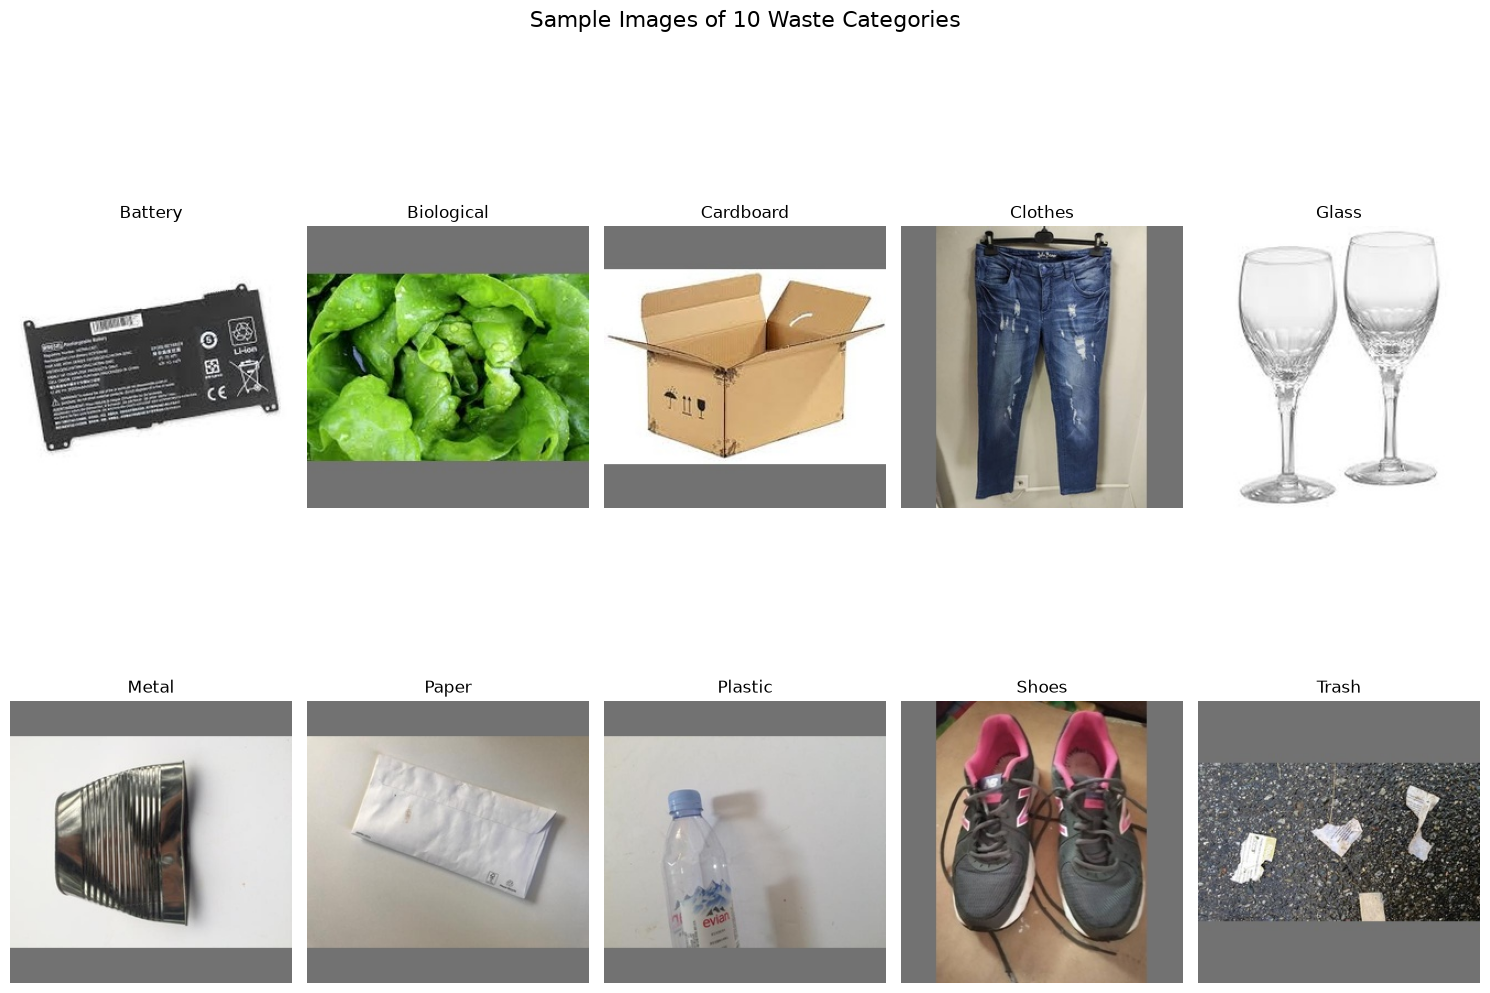

In [8]:
# Display sample images from each waste category

plt.figure(figsize=(15, 12))

for index, class_name in enumerate(dataset_classes["Training"]):

    class_path = os.path.join(TRAIN_DIR, class_name)

    # Get image files
    images = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(image_extensions)
    ]

    # Select one image
    image_path = os.path.join(class_path, images[0])

    # Load image
    image = tf.keras.utils.load_img(image_path)

    # Display image
    plt.subplot(2, 5, index + 1)
    plt.imshow(image)
    plt.title(class_name.capitalize())
    plt.axis("off")

plt.suptitle(
    "Sample Images of 10 Waste Categories",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 6. Image Preprocessing

Image preprocessing is the process of preparing images
before giving them to the AI model.

In this section:
1. Images are resized to 128 × 128 pixels.
2. Images are divided into batches.
3. Labels are automatically assigned to each category.
4. Training, validation and testing datasets are prepared.

In [9]:
# Image configuration for basic CNN

CNN_IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Load training dataset

train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=CNN_IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

# Load validation dataset

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    VALIDATION_DIR,
    image_size=CNN_IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load testing dataset

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=CNN_IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Store class names

class_names = train_dataset.class_names

print("\nDataset loaded successfully!")

print("Classes:", class_names)

print("Number of classes:", len(class_names))

Found 8581 files belonging to 10 classes.
Found 1839 files belonging to 10 classes.
Found 1839 files belonging to 10 classes.

Dataset loaded successfully!
Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of classes: 10


In [10]:
# Check the shape of images and labels

for images, labels in train_dataset.take(1):

    print("Image batch shape:", images.shape)

    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


## 7. Building and Training the Basic CNN Model

In [11]:
# Number of waste categories
num_classes = len(class_names)

print("Number of Classes:", num_classes)
print("Waste Categories:", class_names)


# Create CNN Model
basic_cnn_model = tf.keras.Sequential([

    # Normalize image pixels from 0-255 to 0-1
    tf.keras.layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    # First Convolution Layer
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolution Layer
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third Convolution Layer
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten the extracted features
    tf.keras.layers.Flatten(),

    # Fully Connected Layers
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    # Output Layer
    tf.keras.layers.Dense(num_classes, activation='softmax')
])


# Compile the CNN Model
basic_cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# Display Model Architecture
basic_cnn_model.summary()

Number of Classes: 10
Waste Categories: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


C:\Users\DELL\Documents\EcoSort-AI\.venv311\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ rescaling (Rescaling)     │ (None, 128, 128, 3) │          0 │
├───────────────────────────┼─────────────────────┼────────────┤
│ conv2d (Conv2D)           │ (None, 126, 126,    │        896 │
│                           │ 32)                 │            │
├───────────────────────────┼─────────────────────┼────────────┤
│ max_pooling2d             │ (None, 63, 63, 32)  │          0 │
│ (MaxPooling2D)            │                     │            │
├───────────────────────────┼─────────────────────┼────────────┤
│ conv2d_1 (Conv2D)         │ (None, 61, 61, 64)  │     18,496 │
├───────────────────────────┼─────────────────────┼────────────┤
│ max_pooling2d_1           │ (None, 30, 30, 64)  │          0 │
│ (MaxPooling2D)            │                     │            │
├───────────────────────────┼─────────────────────┼────────────┤
│ conv2d_2 (Conv2D)         │ (None, 28, 28, 128) │     73,856 │
├───────────────────────────┼─────────────────────┼────────────┤
│ max_pooling2d_2           │ (None, 14, 14, 128) │          0 │
│ (MaxPooling2D)            │                     │            │
├───────────────────────────┼─────────────────────┼────────────┤
│ flatten (Flatten)         │ (None, 25088)       │          0 │
├───────────────────────────┼─────────────────────┼────────────┤
│ dense (Dense)             │ (None, 128)         │  3,211,392 │
├───────────────────────────┼─────────────────────┼────────────┤
│ dropout (Dropout)         │ (None, 128)         │          0 │
├───────────────────────────┼─────────────────────┼────────────┤
│ dense_1 (Dense)           │ (None, 10)          │      1,290 │
└───────────────────────────┴─────────────────────┴────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Training the Basic CNN Model

In [12]:
# Create callbacks to improve training

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(MODEL_DIR, "basic_cnn.keras"),
        monitor='val_accuracy',
        save_best_only=True
    )
]


# Train the CNN Model
history = basic_cnn_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15


C:\Users\DELL\Documents\EcoSort-AI\.venv311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


269/269 ━━━━━━━━━━━━━━━━━━━━ 46s 165ms/step - accuracy: 0.3356 - loss: 1.8857 - val_accuracy: 0.5133 - val_loss: 1.4812
Epoch 2/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 42s 154ms/step - accuracy: 0.4877 - loss: 1.4880 - val_accuracy: 0.5633 - val_loss: 1.2716
Epoch 3/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 42s 155ms/step - accuracy: 0.5505 - loss: 1.3179 - val_accuracy: 0.6107 - val_loss: 1.1613
Epoch 4/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 41s 153ms/step - accuracy: 0.5866 - loss: 1.1987 - val_accuracy: 0.6069 - val_loss: 1.1315
Epoch 5/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 42s 154ms/step - accuracy: 0.6279 - loss: 1.0740 - val_accuracy: 0.6514 - val_loss: 1.0532
Epoch 6/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 41s 154ms/step - accuracy: 0.6673 - loss: 0.9782 - val_accuracy: 0.6291 - val_loss: 1.0930
Epoch 7/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 41s 154ms/step - accuracy: 0.6908 - loss: 0.8765 - val_accuracy: 0.6433 - val_loss: 1.0855
Epoch 8/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 41s 153ms/step - accuracy: 0.7210 - loss: 0.7928 - val

## 9. Visualizing CNN Training Accuracy and Loss

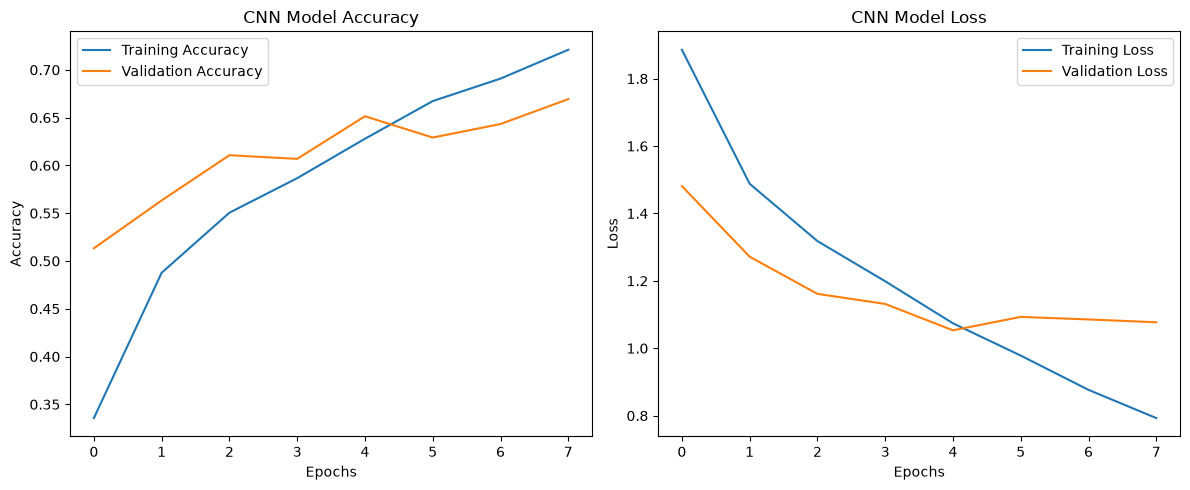

In [13]:
# Plot training and validation accuracy

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()


# Plot training and validation loss

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 10. Evaluating the Basic CNN Model

In [14]:
# Load the best saved CNN model
best_cnn_model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "basic_cnn.keras")
)

# Evaluate the model using testing dataset
test_loss, test_accuracy = best_cnn_model.evaluate(test_dataset)

print("CNN Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("CNN Test Loss:", round(test_loss, 4))

58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.6737 - loss: 1.1433
CNN Test Accuracy: 67.37 %
CNN Test Loss: 1.1433


## 11. CNN Classification Report

In [15]:
from sklearn.metrics import classification_report

# Generate predictions
y_pred_prob = best_cnn_model.predict(test_dataset)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Get actual class labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

# Generate classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step
              precision    recall  f1-score   support

     battery       0.77      0.49      0.60       113
  biological       0.76      0.75      0.76       105
   cardboard       0.73      0.69      0.71       211
     clothes       0.82      0.90      0.86       284
       glass       0.62      0.74      0.67       261
       metal       0.43      0.27      0.33       140
       paper       0.60      0.56      0.58       200
     plastic       0.62      0.67      0.64       240
       shoes       0.64      0.77      0.70       217
       trash       0.77      0.50      0.61        68

    accuracy                           0.67      1839
   macro avg       0.68      0.63      0.65      1839
weighted avg       0.67      0.67      0.67      1839



## 12. CNN Confusion Matrix

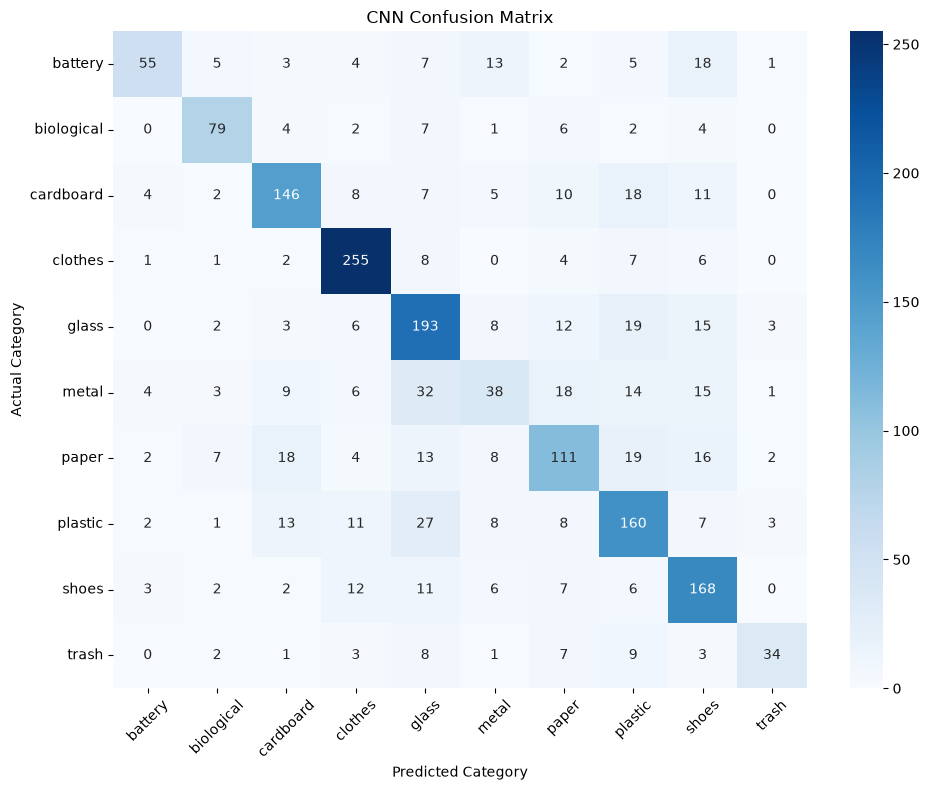

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 13. Preparing Dataset for MobileNetV2

In [17]:
# Import MobileNetV2 preprocessing function
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Set image size and batch size
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

# Load training dataset
mobilenet_train = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    class_names=class_names,
    shuffle=True,
    seed=42
)

# Load validation dataset
mobilenet_validation = tf.keras.utils.image_dataset_from_directory(
    VALIDATION_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    class_names=class_names,
    shuffle=False
)

# Load testing dataset
mobilenet_test = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    class_names=class_names,
    shuffle=False
)

# Apply MobileNetV2 preprocessing
AUTOTUNE = tf.data.AUTOTUNE

mobilenet_train = mobilenet_train.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(AUTOTUNE)

mobilenet_validation = mobilenet_validation.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(AUTOTUNE)

mobilenet_test = mobilenet_test.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(AUTOTUNE)

print("MobileNetV2 datasets prepared successfully!")
print("Image Size:", IMG_SIZE)
print("Number of Classes:", len(class_names))
print("Classes:", class_names)

Found 8581 files belonging to 10 classes.
Found 1839 files belonging to 10 classes.
Found 1839 files belonging to 10 classes.
MobileNetV2 datasets prepared successfully!
Image Size: (160, 160)
Number of Classes: 10
Classes: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


## 14. Loading the Pretrained MobileNetV2 Model

In [18]:
# Import MobileNetV2
from tensorflow.keras.applications import MobileNetV2

# Load pretrained MobileNetV2 model
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(160, 160, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total Layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

# Display model architecture
base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully!
Total Layers: 154
Trainable: False


Model: "mobilenetv2_1.00_160"

┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ Layer (type)     ┃ Output Shape  ┃  Param # ┃ Connected to   ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ input_layer_1    │ (None, 160,   │        0 │ -              │
│ (InputLayer)     │ 160, 3)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ Conv1 (Conv2D)   │ (None, 80,    │      864 │ input_layer_1… │
│                  │ 80, 32)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ bn_Conv1         │ (None, 80,    │      128 │ Conv1[0][0]    │
│ (BatchNormaliza… │ 80, 32)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ Conv1_relu       │ (None, 80,    │        0 │ bn_Conv1[0][0] │
│ (ReLU)           │ 80, 32)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ expanded_conv_d… │ (None, 80,    │      288 │ Conv1_relu[0]… │
│ (DepthwiseConv2… │ 80, 32)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ expanded_conv_d… │ (None, 80,    │      128 │ expanded_conv… │
│ (BatchNormaliza… │ 80, 32)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ expanded_conv_d… │ (None, 80,    │        0 │ expanded_conv… │
│ (ReLU)           │ 80, 32)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ expanded_conv_p… │ (None, 80,    │      512 │ expanded_conv… │
│ (Conv2D)         │ 80, 16)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ expanded_conv_p… │ (None, 80,    │       64 │ expanded_conv… │
│ (BatchNormaliza… │ 80, 16)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_expand   │ (None, 80,    │    1,536 │ expanded_conv… │
│ (Conv2D)         │ 80, 96)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_expand_… │ (None, 80,    │      384 │ block_1_expan… │
│ (BatchNormaliza… │ 80, 96)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_expand_… │ (None, 80,    │        0 │ block_1_expan… │
│ (ReLU)           │ 80, 96)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_pad      │ (None, 81,    │        0 │ block_1_expan… │
│ (ZeroPadding2D)  │ 81, 96)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_depthwi… │ (None, 40,    │      864 │ block_1_pad[0… │
│ (DepthwiseConv2… │ 40, 96)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_depthwi… │ (None, 40,    │      384 │ block_1_depth… │
│ (BatchNormaliza… │ 40, 96)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_depthwi… │ (None, 40,    │        0 │ block_1_depth… │
│ (ReLU)           │ 40, 96)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_project  │ (None, 40,    │    2,304 │ block_1_depth… │
│ (Conv2D)         │ 40, 24)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_1_project… │ (None, 40,    │       96 │ block_1_proje… │
│ (BatchNormaliza… │ 40, 24)       │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_2_expand   │ (None, 40,    │    3,456 │ block_1_proje… │
│ (Conv2D)         │ 40, 144)      │          │                │
├──────────────────┼───────────────┼──────────┼────────────────┤
│ block_2_expand_… │ (None, 40,    │      576 │ block_2_expan… │
│ (BatchNormaliza… │ 40, 144)      

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

## 15. Building the EcoSort AI MobileNetV2 Model

In [19]:
# Define input layer
inputs = tf.keras.Input(shape=(160, 160, 3))

# Extract features using pretrained MobileNetV2
x = base_model(inputs, training=False)

# Reduce feature dimensions
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Add dropout to reduce overfitting
x = tf.keras.layers.Dropout(0.2)(x)

# Output layer for 10 waste categories
outputs = tf.keras.layers.Dense(
    num_classes,
    activation='softmax'
)(x)

# Create final model
mobilenet_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs
)

# Compile model
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary
mobilenet_model.summary()

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape        ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ input_layer_2             │ (None, 160, 160, 3) │          0 │
│ (InputLayer)              │                     │            │
├───────────────────────────┼─────────────────────┼────────────┤
│ mobilenetv2_1.00_160      │ (None, 5, 5, 1280)  │  2,257,984 │
│ (Functional)              │                     │            │
├───────────────────────────┼─────────────────────┼────────────┤
│ global_average_pooling2d  │ (None, 1280)        │          0 │
│ (GlobalAveragePooling2D)  │                     │            │
├───────────────────────────┼─────────────────────┼────────────┤
│ dropout_1 (Dropout)       │ (None, 1280)        │          0 │
├───────────────────────────┼─────────────────────┼────────────┤
│ dense_2 (Dense)           │ (None, 10)          │     12,810 │
└───────────────────────────┴─────────────────────┴────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 16. Training the MobileNetV2 Model

In [20]:
# Create callbacks for MobileNetV2

mobilenet_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            MODEL_DIR,
            "mobilenetv2_best.keras"
        ),
        monitor='val_accuracy',
        save_best_only=True
    )
]


# Train MobileNetV2
history_mobilenet = mobilenet_model.fit(
    mobilenet_train,
    validation_data=mobilenet_validation,
    epochs=10,
    callbacks=mobilenet_callbacks
)

Epoch 1/10


C:\Users\DELL\Documents\EcoSort-AI\.venv311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


269/269 ━━━━━━━━━━━━━━━━━━━━ 53s 185ms/step - accuracy: 0.7624 - loss: 0.7388 - val_accuracy: 0.8673 - val_loss: 0.3950
Epoch 2/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 49s 180ms/step - accuracy: 0.8706 - loss: 0.3872 - val_accuracy: 0.8847 - val_loss: 0.3424
Epoch 3/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 49s 182ms/step - accuracy: 0.8944 - loss: 0.3164 - val_accuracy: 0.8869 - val_loss: 0.3251
Epoch 4/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 49s 180ms/step - accuracy: 0.9106 - loss: 0.2744 - val_accuracy: 0.8880 - val_loss: 0.3245
Epoch 5/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 49s 180ms/step - accuracy: 0.9171 - loss: 0.2429 - val_accuracy: 0.8983 - val_loss: 0.3231
Epoch 6/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 49s 181ms/step - accuracy: 0.9238 - loss: 0.2233 - val_accuracy: 0.8967 - val_loss: 0.3141
Epoch 7/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 49s 183ms/step - accuracy: 0.9280 - loss: 0.2088 - val_accuracy: 0.9021 - val_loss: 0.3081
Epoch 8/10
269/269 ━━━━━━━━━━━━━━━━━━━━ 49s 181ms/step - accuracy: 0.9356 - loss: 0.1920 - val

## 17. Evaluating the MobileNetV2 Model

In [21]:
# Load the best saved MobileNetV2 model

best_mobilenet_model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "mobilenetv2_best.keras")
)

# Evaluate using testing dataset

mobilenet_test_loss, mobilenet_test_accuracy = (
    best_mobilenet_model.evaluate(mobilenet_test)
)

print("MobileNetV2 Test Accuracy:",
      round(mobilenet_test_accuracy * 100, 2), "%")

print("MobileNetV2 Test Loss:",
      round(mobilenet_test_loss, 4))

58/58 ━━━━━━━━━━━━━━━━━━━━ 12s 165ms/step - accuracy: 0.8983 - loss: 0.3071
MobileNetV2 Test Accuracy: 89.83 %
MobileNetV2 Test Loss: 0.3071


## 18. MobileNetV2 Classification Report

In [22]:
# Generate predictions

mobilenet_predictions = best_mobilenet_model.predict(
    mobilenet_test
)

# Convert predictions into class labels

mobilenet_y_pred = np.argmax(
    mobilenet_predictions,
    axis=1
)

# Get actual labels

mobilenet_y_true = np.concatenate([
    labels.numpy()
    for images, labels in mobilenet_test
])

# Display classification report

print(classification_report(
    mobilenet_y_true,
    mobilenet_y_pred,
    target_names=class_names
))

58/58 ━━━━━━━━━━━━━━━━━━━━ 11s 178ms/step
              precision    recall  f1-score   support

     battery       0.96      0.95      0.95       113
  biological       0.95      0.94      0.95       105
   cardboard       0.86      0.92      0.89       211
     clothes       0.99      0.98      0.98       284
       glass       0.86      0.87      0.87       261
       metal       0.86      0.78      0.82       140
       paper       0.86      0.84      0.85       200
     plastic       0.82      0.85      0.84       240
       shoes       0.97      0.97      0.97       217
       trash       0.85      0.75      0.80        68

    accuracy                           0.90      1839
   macro avg       0.90      0.89      0.89      1839
weighted avg       0.90      0.90      0.90      1839



## 19. MobileNetV2 Confusion Matrix

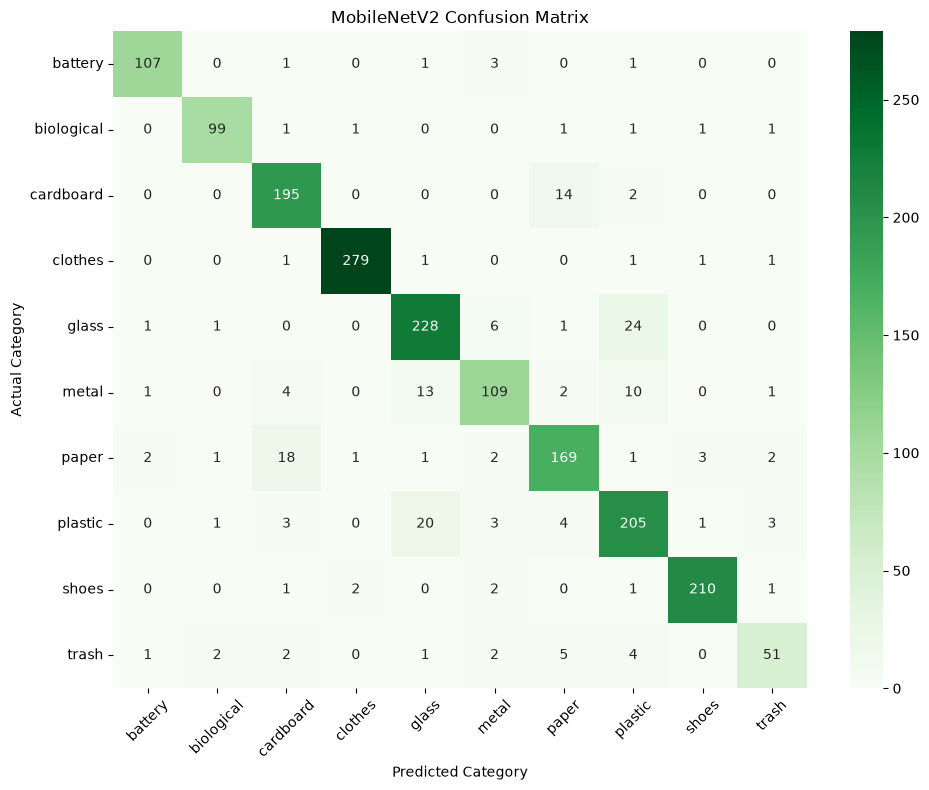

In [23]:
# Create confusion matrix

mobilenet_cm = confusion_matrix(
    mobilenet_y_true,
    mobilenet_y_pred
)

# Display confusion matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## 20. Comparison of CNN and MobileNetV2 Models

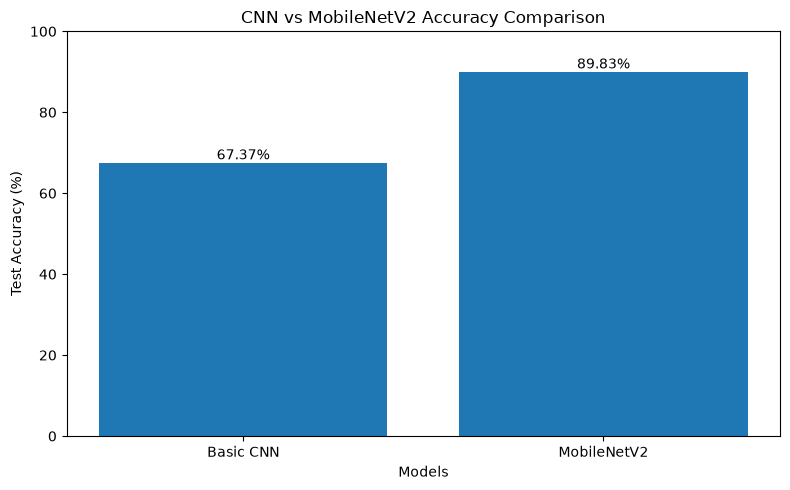

In [24]:
# Model accuracy comparison

models = ['Basic CNN', 'MobileNetV2']

accuracies = [
    67.37,
    89.83
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, accuracies)

plt.title('CNN vs MobileNetV2 Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f'{accuracy}%',
        ha='center'
    )

plt.tight_layout()
plt.show()

## 21. Saving the Final EcoSort AI Model

In [ ]:
# Save final MobileNetV2 model

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "EcoSort_AI_Final_Model.keras"
)

best_mobilenet_model.save(FINAL_MODEL_PATH)

print("Final model saved successfully!")
print("Model Location:", FINAL_MODEL_PATH)